# Análisis Exploratorio de Datos (EDA) — Bank Account Fraud (`Base.csv`)
**Proyecto:** `fraud-detection-crisp-ml` | **Metodología:** CRISP-ML(Q) — Fase 2 (*Data Understanding & Data Preparation*)  
**Dataset:** *Bank Account Fraud (BAF) Dataset Suite* (Jesus et al., NeurIPS 2022, licencia `CC BY-NC-SA 4.0`, cero PII)  
**Regla arquitectónica:** Este notebook contiene **exclusivamente análisis exploratorio descriptivo y visual**. Toda la lógica productiva de partición, preprocesamiento sin *data leakage*, validación cruzada y entrenamiento reside modularmente en `src/`.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    CATEGORICAL_COLS,
    DEFAULT_SAMPLE_SIZE,
    EXPERIMENTS_DIR,
    MISSING_NEGATIVE_COLS,
    NUMERIC_COLS,
    PROTECTED_SUBGROUP_COLS,
    RAW_BAF_PATH,
    SEED,
    TARGET_COL,
    TEMPORAL_COL,
)
from src.data.loader import create_stratified_splits, load_baf_dataframe

FIGURES_DIR = EXPERIMENTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 120

print(f"Raíz del proyecto : {PROJECT_ROOT}")
print(f"Archivo de datos  : {RAW_BAF_PATH} (existe={RAW_BAF_PATH.is_file()})")
print(f"Directorio figuras: {FIGURES_DIR}")

Raíz del proyecto : C:\Users\ccard\fraud-detection-crisp-ml
Archivo de datos  : C:\Users\ccard\fraud-detection-crisp-ml\data\raw\Base.csv (existe=True)
Directorio figuras: C:\Users\ccard\fraud-detection-crisp-ml\experiments\figures


## 1. Carga Eficiente en RAM y Verificación de Integridad (`1M` vs. Muestra Estratificada `100k`)
Se contrasta el dataset completo (`1.000.000` de solicitudes, `32` columnas) cargado con los tipos compactos de `src/data/loader.py` (`float32`/`int32`/`int8`/`category`) frente a la muestra estratificada determinista (`sample_size=100_000`, `seed=42`) y su partición libre de fuga `70% Train / 15% Val / 15% Test`.

In [2]:
df_full, sha256_hex = load_baf_dataframe(csv_path=RAW_BAF_PATH, sample_size=None, seed=SEED)
df_sample, _ = load_baf_dataframe(csv_path=RAW_BAF_PATH, sample_size=DEFAULT_SAMPLE_SIZE, seed=SEED)
splits = create_stratified_splits(df_sample, dataset_sha256=sha256_hex, seed=SEED)

full_mem_mb = df_full.memory_usage(deep=True).sum() / (1024 ** 2)
summary_df = pd.DataFrame(
    [
        {
            "Conjunto": "BAF Base.csv Completo (1M)",
            "Filas": len(df_full),
            "Fraudes (y=1)": int(df_full[TARGET_COL].sum()),
            "Prevalencia (%)": round(100 * float(df_full[TARGET_COL].mean()), 4),
            "Memoria Optimizada (MB)": round(float(full_mem_mb), 2),
        },
        {
            "Conjunto": "Muestra Estratificada (100k, seed=42)",
            "Filas": splits.total_rows_loaded,
            "Fraudes (y=1)": int(df_sample[TARGET_COL].sum()),
            "Prevalencia (%)": round(100 * splits.fraud_rate, 4),
            "Memoria Optimizada (MB)": splits.memory_usage_mb,
        },
        {
            "Conjunto": "Split Train (70%)",
            "Filas": len(splits.y_train),
            "Fraudes (y=1)": int(splits.y_train.sum()),
            "Prevalencia (%)": round(100 * float(splits.y_train.mean()), 4),
            "Memoria Optimizada (MB)": round(float(splits.X_train.memory_usage(deep=True).sum() / (1024 ** 2)), 2),
        },
        {
            "Conjunto": "Split Val (15%)",
            "Filas": len(splits.y_val),
            "Fraudes (y=1)": int(splits.y_val.sum()),
            "Prevalencia (%)": round(100 * float(splits.y_val.mean()), 4),
            "Memoria Optimizada (MB)": round(float(splits.X_val.memory_usage(deep=True).sum() / (1024 ** 2)), 2),
        },
        {
            "Conjunto": "Split Test (15%)",
            "Filas": len(splits.y_test),
            "Fraudes (y=1)": int(splits.y_test.sum()),
            "Prevalencia (%)": round(100 * float(splits.y_test.mean()), 4),
            "Memoria Optimizada (MB)": round(float(splits.X_test.memory_usage(deep=True).sum() / (1024 ** 2)), 2),
        },
    ]
)
print(f"SHA-256 verificado: {sha256_hex}")
print(f"Nulos explícitos NaN en CSV crudo: {int(df_full.isna().sum().sum())}")
print(f"Varianza de device_fraud_count (1M): {float(df_full['device_fraud_count'].var()):.6f} (constante=0)")
print(summary_df.to_string(index=False))

SHA-256 verificado: 7bf10a37ce07e72e14c1b09e5efee3d27261baff4facc7da767b0474dcf9b809
Nulos explícitos NaN en CSV crudo: 0
Varianza de device_fraud_count (1M): 0.000000 (constante=0)
                             Conjunto   Filas  Fraudes (y=1)  Prevalencia (%)  Memoria Optimizada (MB)
           BAF Base.csv Completo (1M) 1000000          11029           1.1029                    84.88
Muestra Estratificada (100k, seed=42)  100000           1103           1.1030                     8.49
                    Split Train (70%)   70000            772           1.1029                     5.88
                      Split Val (15%)   15000            166           1.1067                     1.26
                     Split Test (15%)   15000            165           1.1000                     1.26


## 2. (a) Desbalance Severo de la Variable Objetivo (`fraud_bool`)
La tasa basal de fraude es **`1.1029%`** (razón aproximada **`1 : 89.7`** entre solicitudes fraudulentas y legítimas). Este desbalance extremo invalida el *accuracy* (un clasificador trivial que aprueba todo obtendría `98.90%` de exactitud con `Recall = 0%`) y justifica el uso de **`AUC-PR` (`ap`)** como métrica primaria y **`Recall@FPR<=5%`** como restricción operativa.

[Exportada] C:\Users\ccard\fraud-detection-crisp-ml\experiments\figures\01_class_imbalance.png


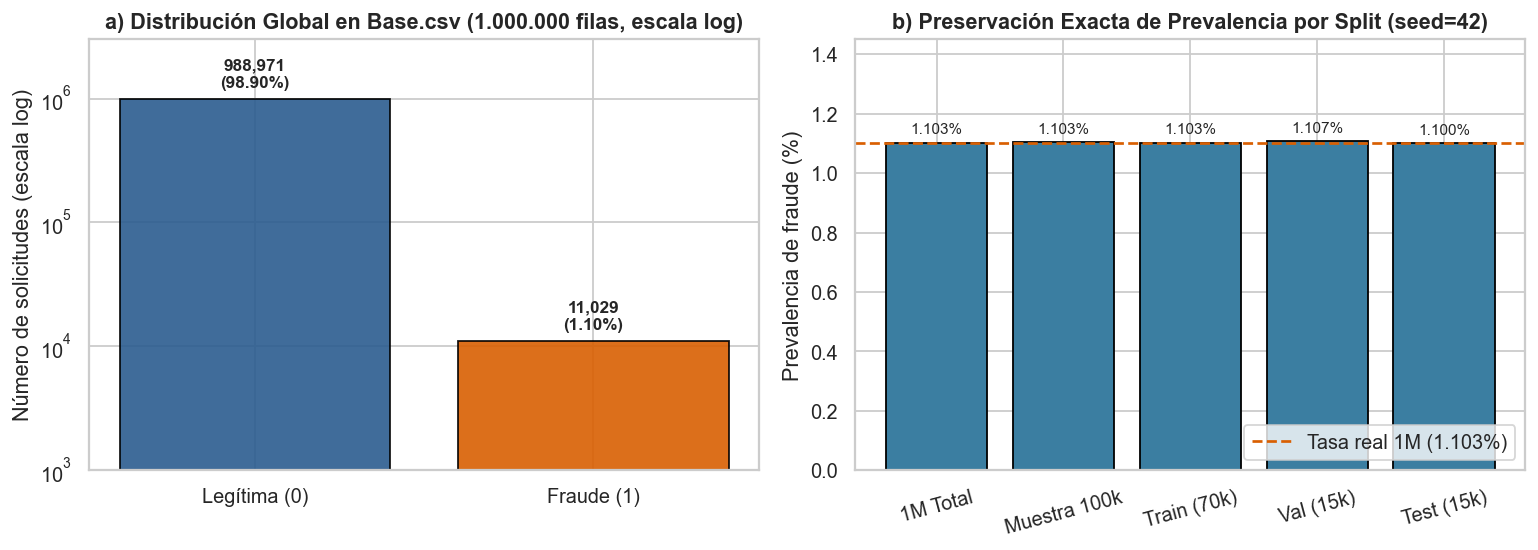

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

counts_1m = df_full[TARGET_COL].value_counts().sort_index()
bars = axes[0].bar(
    ["Legítima (0)", "Fraude (1)"],
    counts_1m.values,
    color=["#2b5c8f", "#d95f02"],
    edgecolor="black",
     alpha=0.9,
)
axes[0].set_yscale("log")
axes[0].set_title("a) Distribución Global en Base.csv (1.000.000 filas, escala log)", fontweight="bold")
axes[0].set_ylabel("Número de solicitudes (escala log)")
for bar, cnt in zip(bars, counts_1m.values):
    pct = 100.0 * cnt / len(df_full)
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        cnt * 1.18,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )
axes[0].set_ylim(1e3, 3e6)

split_labels = ["1M Total", "Muestra 100k", "Train (70k)", "Val (15k)", "Test (15k)"]
split_rates = [
    100 * float(df_full[TARGET_COL].mean()),
    100 * float(df_sample[TARGET_COL].mean()),
    100 * float(splits.y_train.mean()),
    100 * float(splits.y_val.mean()),
    100 * float(splits.y_test.mean()),
]
bars2 = axes[1].bar(split_labels, split_rates, color="#3b7ea1", edgecolor="black")
axes[1].axhline(split_rates[0], color="#d95f02", linestyle="--", linewidth=1.5, label=f"Tasa real 1M ({split_rates[0]:.3f}%)")
axes[1].set_title("b) Preservación Exacta de Prevalencia por Split (seed=42)", fontweight="bold")
axes[1].set_ylabel("Prevalencia de fraude (%)")
axes[1].set_ylim(0, 1.45)
axes[1].tick_params(axis="x", rotation=15)
for bar, rate in zip(bars2, split_rates):
    axes[1].text(bar.get_x() + bar.get_width() / 2, rate + 0.03, f"{rate:.3f}%", ha="center", fontsize=8.5)
axes[1].legend(loc="lower right")

plt.tight_layout()
fig_path_1 = FIGURES_DIR / "01_class_imbalance.png"
fig.savefig(fig_path_1, dpi=180, bbox_inches="tight")
plt.show()
print(f"[Exportada] {fig_path_1}")

## 3. (b) Mapa de Valores Faltantes Codificados como Centinelas Negativos (`< 0`) vs. Negativos de Dominio
En BAF `Base.csv` no existen `NaN` literales; los valores faltantes o "no aplica" fueron codificados con valores negativos (`-1` o `< 0`) en 6 columnas documentadas (`MISSING_NEGATIVE_COLS`). Sin embargo, inspeccionar todas las columnas numéricas revela una distinción crítica de ingeniería:
- **`MISSING_NEGATIVE_COLS`** (`prev_address_months_count`, `intended_balcon_amount`, `bank_months_count`, `current_address_months_count`, `session_length_in_minutes`, `device_distinct_emails_8w`): valores negativos corresponden a centinelas de ausencia y exhiben tasas de fraude diferenciadas (justificando `SimpleImputer(strategy="median", add_indicator=True)`).
- **`credit_risk_score`**: presenta valores negativos continuos hasta `-170` que son **puntajes crediticios reales válidos**, **no** datos faltantes; convertirlos a `NaN` destruiría información predictiva de alto valor.
- **`device_fraud_count`**: vale exactamente `0` en los `1.000.000` de registros (`varianza = 0.0`), por lo que el preprocesador la descarta limpiamente in-fold mediante `VarianceThreshold(threshold=0.0)`.

                     columna  pct_negativos  es_centinela_faltante         min  tasa_fraude_si_neg_%  tasa_fraude_si_pos_%
                 velocity_6h          0.006                  False -155.430725              0.000000              1.103066
   device_distinct_emails_8w          0.034                   True   -1.000000              0.000000              1.103375
   session_length_in_minutes          0.200                   True   -1.000000              0.500000              1.104208
current_address_months_count          0.453                   True   -1.000000              0.441501              1.106010
           credit_risk_score          1.478                  False -169.000000              0.202977              1.116502
           bank_months_count         25.658                   True   -1.000000              1.578455              0.938904
   prev_address_months_count         71.118                   True   -1.000000              1.432830              0.290839
      intended_b

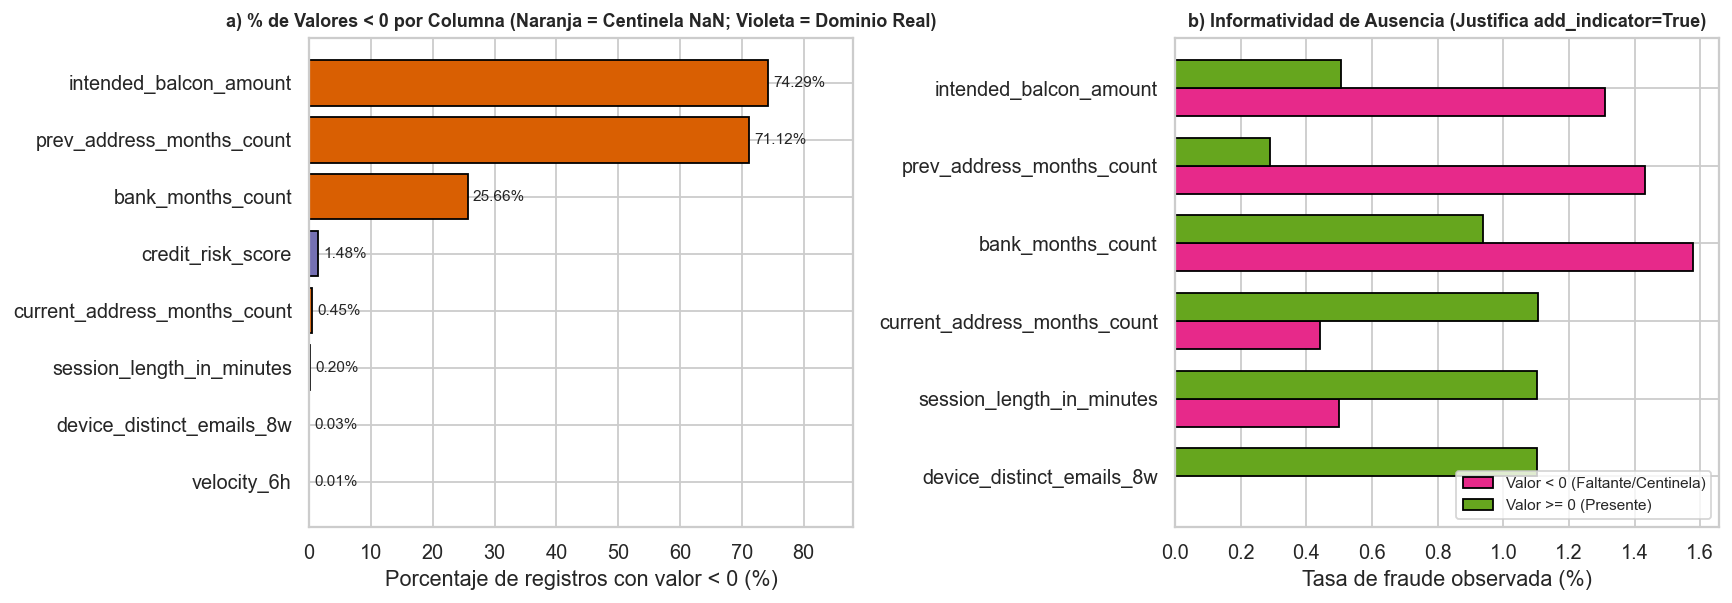

In [4]:
neg_rows = []
for col in NUMERIC_COLS:
    s = df_sample[col]
    neg_mask = s < 0
    if neg_mask.any() or col in MISSING_NEGATIVE_COLS:
        neg_rows.append(
            {
                "columna": col,
                "pct_negativos": 100.0 * float(neg_mask.mean()),
                "es_centinela_faltante": col in MISSING_NEGATIVE_COLS,
                "min": float(s.min()),
                "tasa_fraude_si_neg_%": 100.0 * float(df_sample.loc[neg_mask, TARGET_COL].mean()) if neg_mask.any() else 0.0,
                "tasa_fraude_si_pos_%": 100.0 * float(df_sample.loc[~neg_mask, TARGET_COL].mean()),
            }
        )

neg_df = pd.DataFrame(neg_rows).sort_values("pct_negativos", ascending=True)
print(neg_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

colors = ["#d95f02" if flag else "#7570b3" for flag in neg_df["es_centinela_faltante"]]
axes[0].barh(neg_df["columna"], neg_df["pct_negativos"], color=colors, edgecolor="black")
axes[0].set_title("a) % de Valores < 0 por Columna (Naranja = Centinela NaN; Violeta = Dominio Real)", fontsize=10, fontweight="bold")
axes[0].set_xlabel("Porcentaje de registros con valor < 0 (%)")
for idx, row in enumerate(neg_df.itertuples()):
    axes[0].text(row.pct_negativos + 0.8, idx, f"{row.pct_negativos:.2f}%", va="center", fontsize=8.5)
axes[0].set_xlim(0, 88)

sent_only = neg_df[neg_df["es_centinela_faltante"]].copy()
y_pos = np.arange(len(sent_only))
w = 0.36
axes[1].barh(y_pos - w / 2, sent_only["tasa_fraude_si_neg_%"], height=w, label="Valor < 0 (Faltante/Centinela)", color="#e7298a", edgecolor="black")
axes[1].barh(y_pos + w / 2, sent_only["tasa_fraude_si_pos_%"], height=w, label="Valor >= 0 (Presente)", color="#66a61e", edgecolor="black")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(sent_only["columna"])
axes[1].set_xlabel("Tasa de fraude observada (%)")
axes[1].set_title("b) Informatividad de Ausencia (Justifica add_indicator=True)", fontsize=10, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
fig_path_2 = FIGURES_DIR / "02_missing_sentinels_map.png"
fig.savefig(fig_path_2, dpi=180, bbox_inches="tight")
plt.show()
print(f"[Exportada] {fig_path_2}")

## 4. (c) Dinámica Temporal de Solicitudes y Tasa de Fraude (`month` `0`–`7`)
El dataset abarca 8 meses consecutivos (`month` de `0` a `7`). Analizar su evolución permite verificar tanto la fidelidad del muestreo estratificado conjunto `(fraud_bool, month)` como la naturaleza no estacionaria de los patrones de ataque en canales digitales.

 month  solicitudes_1m  tasa_fraude_1m  solicitudes_100k  tasa_fraude_100k
     0          132440        1.132588             13244          1.132588
     1          127620        0.938724             12762          0.940291
     2          136979        0.874587             13698          0.876040
     3          150936        0.922245             15093          0.920957
     4          127691        1.137120             12769          1.135563
     5          119323        1.182505             11932          1.181696
     6          108168        1.340507             10817          1.340483
     7           96843        1.474552              9685          1.476510
[Exportada] C:\Users\ccard\fraud-detection-crisp-ml\experiments\figures\03_temporal_dynamics_month.png


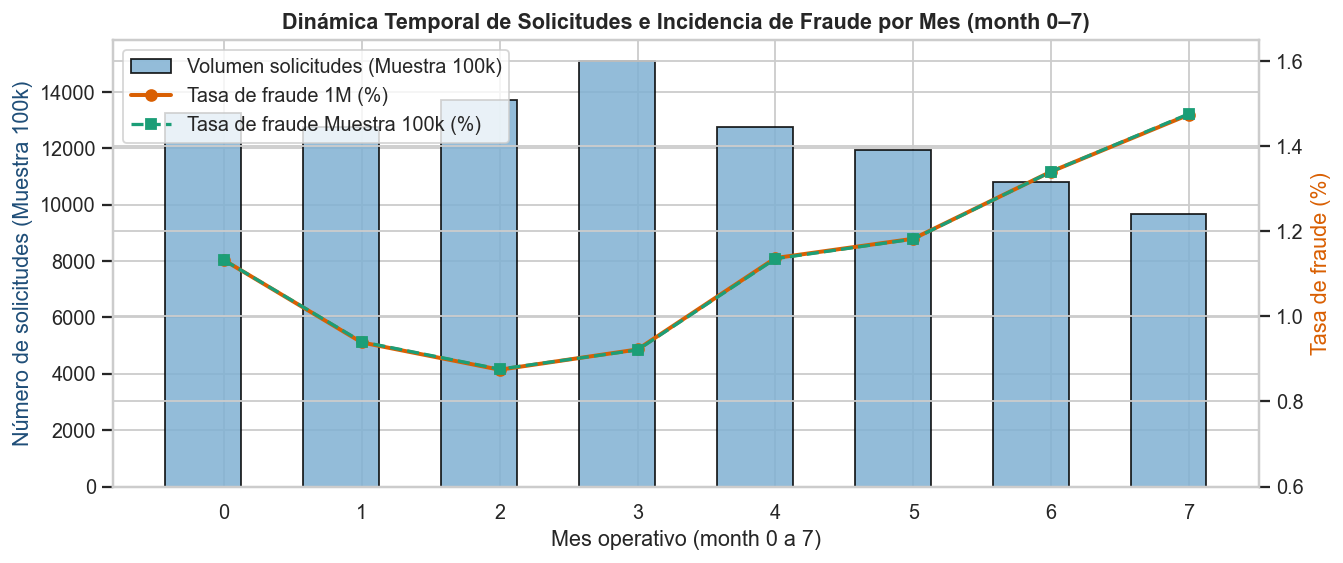

In [5]:
temporal_1m = (
    df_full.groupby(TEMPORAL_COL, observed=False)[TARGET_COL]
    .agg(solicitudes_1m="count", tasa_fraude_1m=lambda s: 100.0 * float(s.mean()))
    .reset_index()
)
temporal_100k = (
    df_sample.groupby(TEMPORAL_COL, observed=False)[TARGET_COL]
    .agg(solicitudes_100k="count", tasa_fraude_100k=lambda s: 100.0 * float(s.mean()))
    .reset_index()
)
temp_merged = temporal_1m.merge(temporal_100k, on=TEMPORAL_COL)
print(temp_merged.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(10.5, 4.5))
bars = ax1.bar(
    temp_merged[TEMPORAL_COL] - 0.15,
    temp_merged["solicitudes_100k"],
    width=0.55,
    color="#80b1d3",
    edgecolor="black",
    alpha=0.85,
    label="Volumen solicitudes (Muestra 100k)",
)
ax1.set_xlabel("Mes operativo (month 0 a 7)")
ax1.set_ylabel("Número de solicitudes (Muestra 100k)", color="#1f4e78")
ax1.set_xticks(range(8))

ax2 = ax1.twinx()
ax2.plot(
    temp_merged[TEMPORAL_COL],
    temp_merged["tasa_fraude_1m"],
    marker="o",
    linewidth=2.2,
    color="#d95f02",
    label="Tasa de fraude 1M (%)",
)
ax2.plot(
    temp_merged[TEMPORAL_COL],
    temp_merged["tasa_fraude_100k"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    color="#1b9e77",
    label="Tasa de fraude Muestra 100k (%)",
)
ax2.set_ylabel("Tasa de fraude (%)", color="#d95f02")
ax2.set_ylim(0.6, 1.65)
ax1.set_title("Dinámica Temporal de Solicitudes e Incidencia de Fraude por Mes (month 0–7)", fontweight="bold")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", frameon=True)

plt.tight_layout()
fig_path_3 = FIGURES_DIR / "03_temporal_dynamics_month.png"
fig.savefig(fig_path_3, dpi=180, bbox_inches="tight")
plt.show()
print(f"[Exportada] {fig_path_3}")

## 5. (d) Distribuciones Comparativas de Variables Predictoras Clave
Se contrastan las distribuciones condicionales por clase (`fraud_bool = 0` vs. `fraud_bool = 1`) sobre la muestra de `100.000` solicitudes para identificar señal discriminativa lineal y no lineal antes del modelado.

Medias por clase (fraud_bool=0 vs 1):
            credit_risk_score  name_email_similarity  proposed_credit_limit  income  customer_age
fraud_bool                                                                                       
0                     130.339                  0.493             512.822998   0.562        33.582
1                     177.806                  0.373             842.439026   0.688        40.780
[Exportada] C:\Users\ccard\fraud-detection-crisp-ml\experiments\figures\04_key_predictors_distributions.png


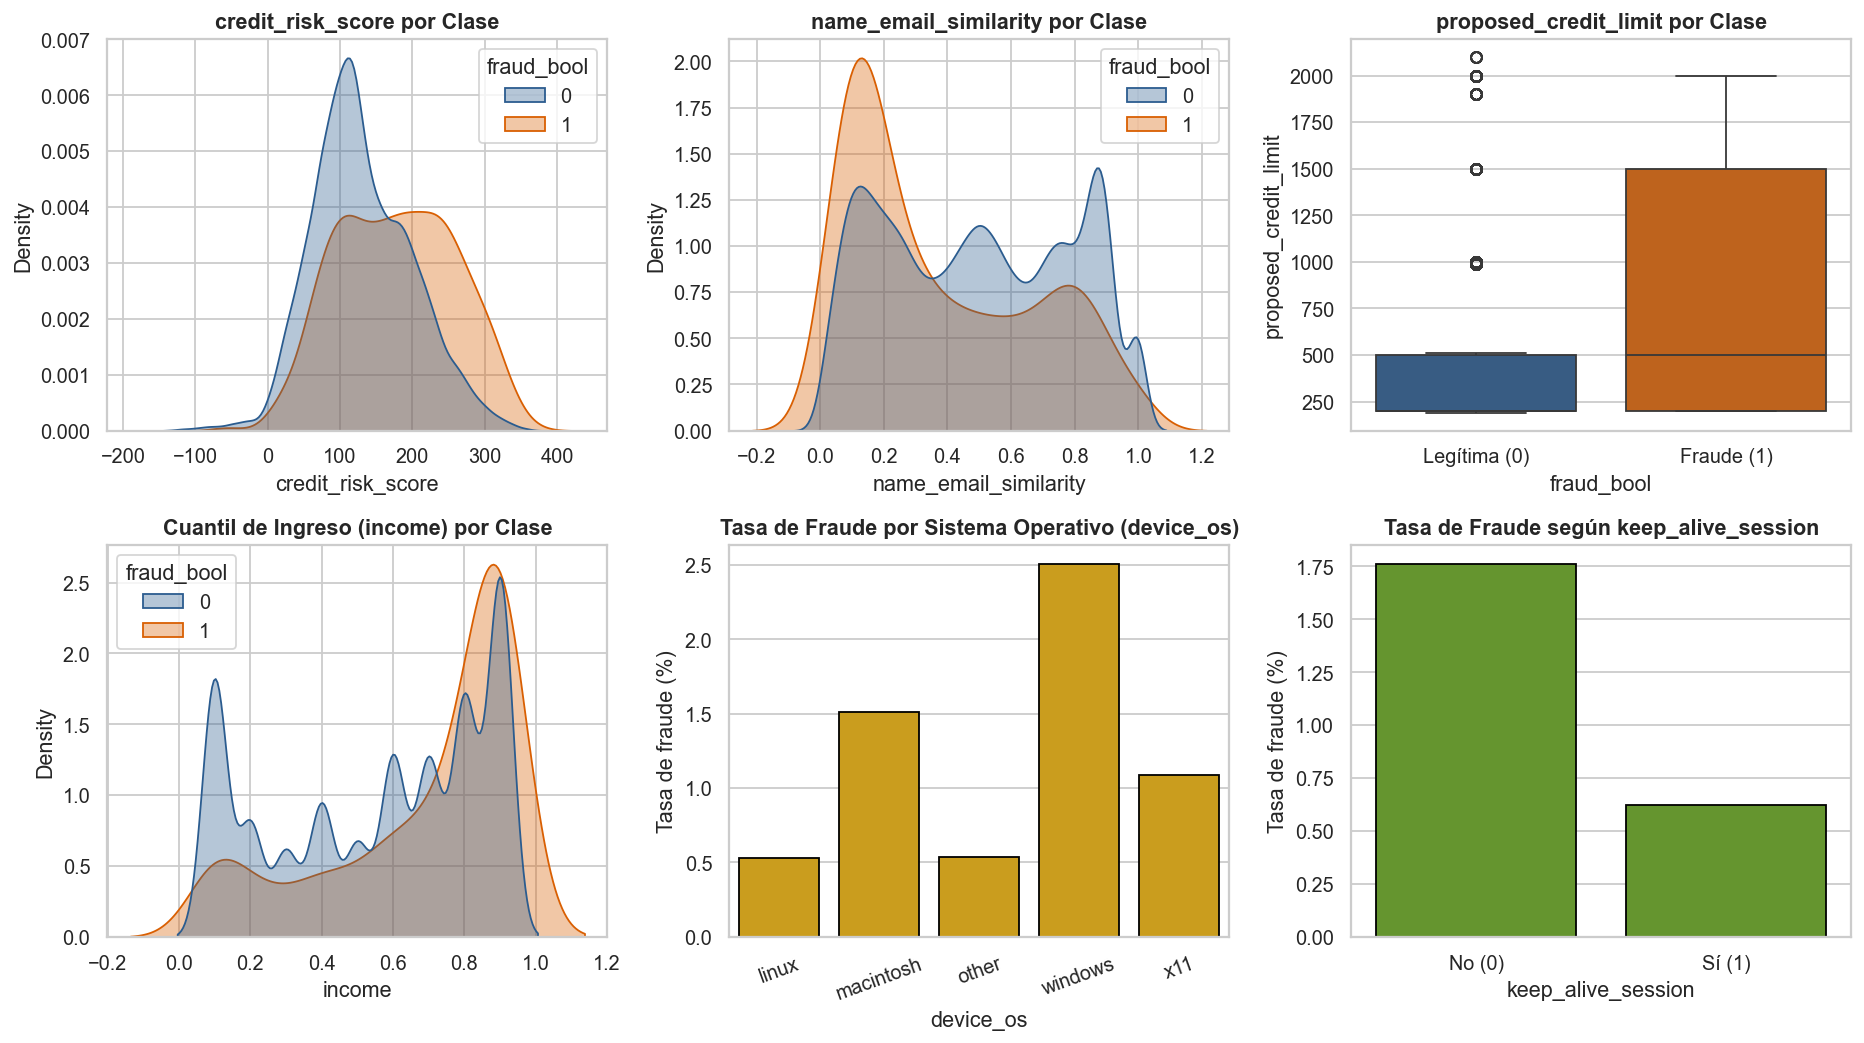

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.2))
palette_cls = {0: "#2b5c8f", 1: "#d95f02"}

# 1. credit_risk_score
sns.kdeplot(
    data=df_sample, x="credit_risk_score", hue=TARGET_COL, common_norm=False,
    fill=True, alpha=0.35, palette=palette_cls, ax=axes[0, 0]
)
axes[0, 0].set_title("credit_risk_score por Clase", fontweight="bold")

# 2. name_email_similarity
sns.kdeplot(
    data=df_sample, x="name_email_similarity", hue=TARGET_COL, common_norm=False,
    fill=True, alpha=0.35, palette=palette_cls, ax=axes[0, 1]
)
axes[0, 1].set_title("name_email_similarity por Clase", fontweight="bold")

# 3. proposed_credit_limit
sns.boxplot(
    data=df_sample, x=TARGET_COL, y="proposed_credit_limit",
    hue=TARGET_COL, palette=palette_cls, legend=False, ax=axes[0, 2]
)
axes[0, 2].set_xticks([0, 1])
axes[0, 2].set_xticklabels(["Legítima (0)", "Fraude (1)"])
axes[0, 2].set_title("proposed_credit_limit por Clase", fontweight="bold")

# 4. income
sns.kdeplot(
    data=df_sample, x="income", hue=TARGET_COL, common_norm=False,
    fill=True, alpha=0.35, palette=palette_cls, ax=axes[1, 0], bw_adjust=1.2
)
axes[1, 0].set_title("Cuantil de Ingreso (income) por Clase", fontweight="bold")

# 5. Tasa de fraude por device_os
os_rates = (
    df_sample.groupby("device_os", observed=True)[TARGET_COL]
    .agg(count="count", fraud_pct=lambda s: 100.0 * float(s.mean()))
    .sort_values("fraud_pct", ascending=False)
    .reset_index()
)
sns.barplot(
    data=os_rates, x="device_os", y="fraud_pct", color="#e6ab02", edgecolor="black", ax=axes[1, 1]
)
axes[1, 1].set_title("Tasa de Fraude por Sistema Operativo (device_os)", fontweight="bold")
axes[1, 1].set_ylabel("Tasa de fraude (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

# 6. Tasa de fraude según keep_alive_session y phone_home_valid
session_rates = (
    df_sample.groupby("keep_alive_session", observed=True)[TARGET_COL]
    .mean()
    .mul(100.0)
    .reset_index()
)
sns.barplot(
    data=session_rates, x="keep_alive_session", y=TARGET_COL,
    color="#66a61e", edgecolor="black", ax=axes[1, 2]
)
axes[1, 2].set_xticks([0, 1])
axes[1, 2].set_xticklabels(["No (0)", "Sí (1)"])
axes[1, 2].set_ylabel("Tasa de fraude (%)")
axes[1, 2].set_title("Tasa de Fraude según keep_alive_session", fontweight="bold")

plt.tight_layout()
fig_path_4 = FIGURES_DIR / "04_key_predictors_distributions.png"
fig.savefig(fig_path_4, dpi=180, bbox_inches="tight")
plt.show()

# Resumen numérico de medianas/medias por clase
num_compare = (
    df_sample.groupby(TARGET_COL)[
        ["credit_risk_score", "name_email_similarity", "proposed_credit_limit", "income", "customer_age"]
    ]
    .mean()
    .round(3)
)
print("Medias por clase (fraud_bool=0 vs 1):")
print(num_compare.to_string())
print(f"[Exportada] {fig_path_4}")

## 6. (e) Análisis Exploratorio de Subgrupos Demográficos (Riesgo Previo de Sesgo — IA Responsable)
Siguiendo el protocolo de equidad de Jesus et al. (NeurIPS 2022) y los criterios congelados en el Hito 1, inspeccionamos la distribución poblacional y la prevalencia basal de fraude en los tres atributos auditados:
1. **`customer_age`** (`>= 50` vs. `< 50` años).
2. **`employment_status`** (`CA` a `CG`).
3. **`income`** segmentado en bandas (`low_income <= 0.35`, `mid_income (0.35, 0.65]`, `high_income > 0.65`).

**Hipótesis crítica de equidad:** Si un grupo demográfico (ej. solicitantes `>= 50` años o banda `high_income`) presenta mayor tasa basal de fraude o correlación con variables como `proposed_credit_limit` y `customer_age`, un clasificador lineal con umbral global único tenderá a elevar desproporcionadamente su tasa de falsos positivos (`FPR`), arriesgando superar la meta `Delta FPR <= 0.05`.


--- Subgrupo: age_group ---
age_group     n  fraud_pct
  age_<50 81830   0.827325
 age_>=50 18170   2.344524

--- Subgrupo: employment_status ---
employment_status     n  fraud_pct
               CA 72885   1.196405
               CB 13981   0.815392
               CC  3785   2.589168
               CD  2651   0.377216
               CE  2207   0.181242
               CF  4445   0.112486
               CG    46   0.000000

--- Subgrupo: income_band ---
income_band     n  fraud_pct
 low_income 27786   0.608220
 mid_income 24706   0.797377
high_income 47508   1.551318
[Exportada] C:\Users\ccard\fraud-detection-crisp-ml\experiments\figures\05_demographic_subgroups_bias.png


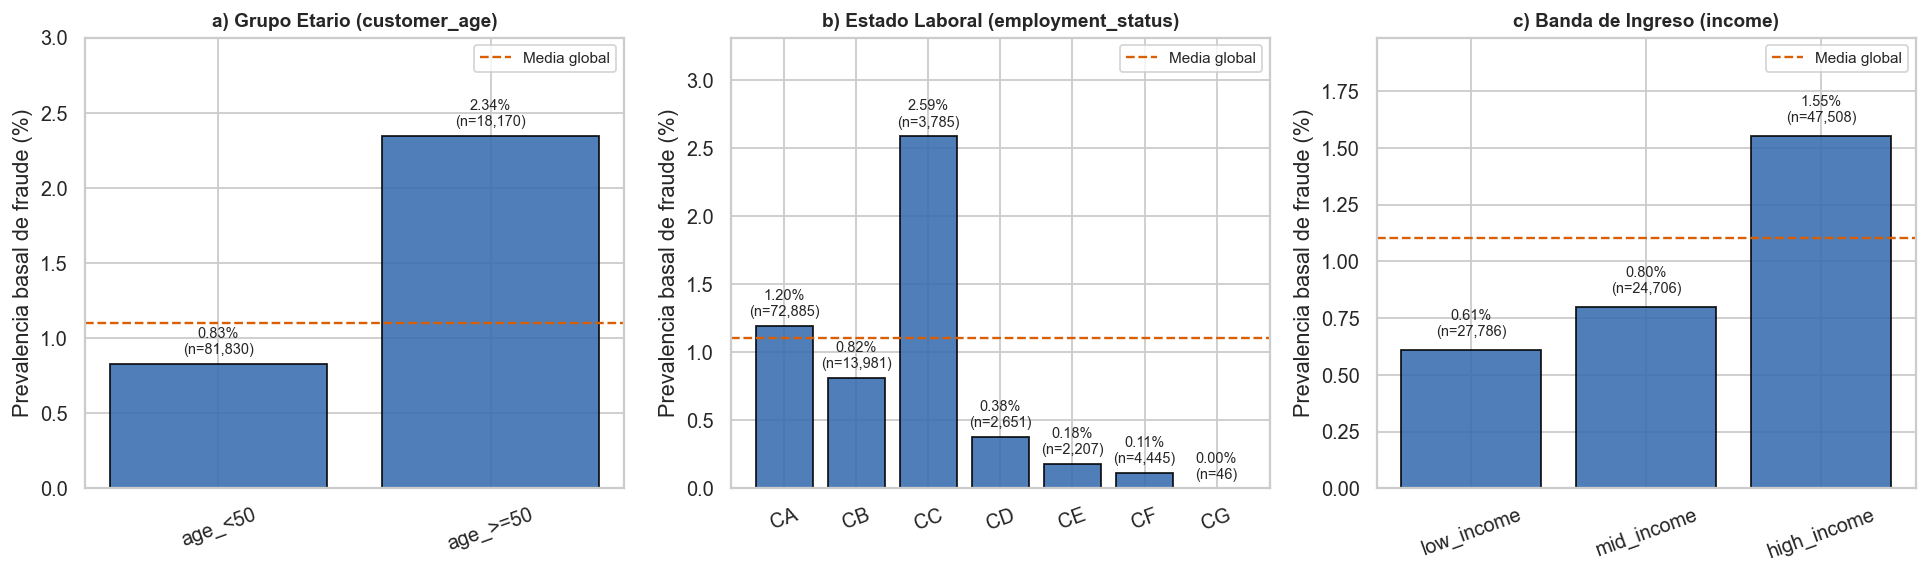

In [7]:
df_demo = df_sample.copy()
df_demo["age_group"] = np.where(df_demo["customer_age"] >= 50, "age_>=50", "age_<50")
df_demo["income_band"] = pd.cut(
    df_demo["income"].astype(float),
    bins=[-np.inf, 0.35, 0.65, np.inf],
    labels=["low_income", "mid_income", "high_income"],
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, col, title in zip(
    axes,
    ["age_group", "employment_status", "income_band"],
    [
        "a) Grupo Etario (customer_age)",
        "b) Estado Laboral (employment_status)",
        "c) Banda de Ingreso (income)",
    ],
):
    stats = (
        df_demo.groupby(col, observed=True)[TARGET_COL]
        .agg(n="count", fraud_pct=lambda s: 100.0 * float(s.mean()))
        .reset_index()
    )
    print(f"\n--- Subgrupo: {col} ---")
    print(stats.to_string(index=False))

    bars = ax.bar(stats[col].astype(str), stats["fraud_pct"], color="#386cb0", edgecolor="black", alpha=0.88)
    ax.axhline(100.0 * float(df_demo[TARGET_COL].mean()), color="#d95f02", linestyle="--", linewidth=1.3, label="Media global")
    ax.set_title(title, fontweight="bold", fontsize=10.5)
    ax.set_ylabel("Prevalencia basal de fraude (%)")
    ax.tick_params(axis="x", rotation=20)
    for bar, row in zip(bars, stats.itertuples()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            row.fraud_pct + 0.05,
            f"{row.fraud_pct:.2f}%\n(n={row.n:,})",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_ylim(0, max(stats["fraud_pct"]) * 1.28)
    ax.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
fig_path_5 = FIGURES_DIR / "05_demographic_subgroups_bias.png"
fig.savefig(fig_path_5, dpi=180, bbox_inches="tight")
plt.show()
print(f"[Exportada] {fig_path_5}")

## 7. Síntesis Ejecutiva de Hallazgos para la Fase 3 (Modelado sin *Data Leakage*)
1. **Compresión sin pérdida predictiva:** El esquema de tipos compactos reduce la huella en memoria de `Base.csv` en **~68–73%** respecto a `float64`/`int64`/`object`, y la muestra de `100.000` registros ocupa apenas **~6.2 MB**, preservando `1.103%` de fraude en `Train`, `Val` y `Test`.
2. **Tratamiento diferenciado de negativos y constantes:** Solo las 6 columnas de `MISSING_NEGATIVE_COLS` deben transformarse mediante `< 0 -> NaN` con indicador de ausencia (`add_indicator=True`); `credit_risk_score` conserva sus valores negativos legítimos y `device_fraud_count` (100% ceros) se elimina in-fold con `VarianceThreshold(0.0)`.
3. **Señal multivariable no lineal y riesgo de sesgo etario:** Los defraudadores se concentran en mayor `credit_risk_score`, menor `name_email_similarity`, mayor `proposed_credit_limit`, `keep_alive_session == 0` y `device_os == windows`. La tasa basal de fraude en `age_>=50` más que duplica la de `age_<50`, anticipando presión sobre `Delta FPR` en clasificadores lineales con umbral global.